# Analyse univariée des variables qualitatives (catégorielles)

Objectif : décrire chaque variable qualitative **séparément** (sans croiser avec la cible) :
- tableau des effectifs, fréquences et fréquences cumulées ;
- indicateurs : nombre de modalités, mode, part du mode, ratio max/min ;
- test d'adéquation du χ² à une répartition uniforme ;
- graphiques (diagramme en barres, barre empilée à 100 %, vue d'ensemble, écarts à l'uniformité, intervalles de confiance, carte des manquants) ;
- interprétation.

Variables étudiées : `Gender` (0 = Femme, 1 = Homme), `Region`, `CityCode`, `ProvPur` (variable cible).

## 1. Chargement et préparation des données

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

# --- Style commun des graphiques ---
# Palette catégorielle (ordre fixe, validée daltonisme) et encres neutres
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLEU, ROUGE = "#2a78d6", "#e34948"          # pôles positif / négatif
FOND, ENCRE, ENCRE_2, GRIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND,
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "text.color": ENCRE, "axes.labelcolor": ENCRE_2,
    "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})
pd.set_option("display.width", 200)

file_id = "1n2IJtB3CaaRTvR3Rs-r3Ipns0PI5uDsc"
url = f"https://drive.google.com/uc?id={file_id}"
df = pd.read_csv(url, sep=";")

CIBLE = "ProvPur"
# Recodage du genre : 0 = Femme, 1 = Homme
df["Gender"] = df["Gender"].map({0: "Femme", 1: "Homme"})

QUALITATIVES = ["Gender", "Region", "CityCode", CIBLE]
for c in QUALITATIVES:
    df[c] = df[c].astype("category")

print("Dimensions :", df.shape)
df[QUALITATIVES].describe()

Dimensions : (4000, 23)


,Gender,Region,CityCode,ProvPur
count,4000,4000,3903,4000
unique,2,4,19,2
top,Femme,NE,M,No
freq,2818,1657,234,3662


## 2. Recherche des valeurs manquantes

Une valeur manquante peut prendre deux formes :
1. une **vraie** valeur manquante (`NaN`), c'est-à-dire une case vide dans le fichier ;
2. une valeur manquante **cachée** : un code qui remplace l'information absente (`"?"`, `"NA"`, `"-"`, `"inconnu"`, espace vide…). pandas ne la reconnaît pas : elle apparaît alors comme une modalité à part entière.

On recherche les deux, puis on regarde si les manquants sont répartis **au hasard**.

### 2.1 Valeurs manquantes explicites (`NaN`)

,Nb manquants,% manquants,Nb renseignés
Gender,0,0.00,4000
Region,0,0.00,4000
CityCode,97,2.43,3903
ProvPur,0,0.00,4000


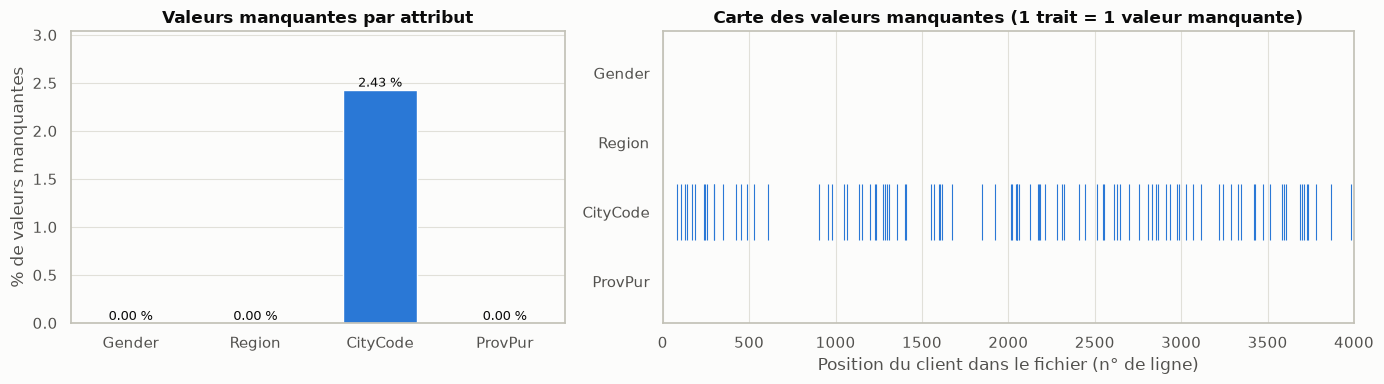

In [17]:
manquants = pd.DataFrame({
    "Nb manquants": df[QUALITATIVES].isna().sum(),
    "% manquants": (df[QUALITATIVES].isna().mean() * 100).round(2),
    "Nb renseignés": df[QUALITATIVES].notna().sum(),
})
display(manquants)

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.4]})

# (a) Pourcentage de manquants par attribut
ax = axes[0]
ax.bar(manquants.index, manquants["% manquants"], color=BLEU, width=0.6)
for i, v in enumerate(manquants["% manquants"]):
    ax.text(i, v, f"{v:.2f} %", ha="center", va="bottom", fontsize=9, color=ENCRE)
ax.set_ylabel("% de valeurs manquantes"); ax.set_title("Valeurs manquantes par attribut")
ax.margins(y=0.25); ax.grid(axis="x", visible=False)

# (b) Carte des manquants : chaque trait = un client dont la valeur manque
ax = axes[1]
for j, c in enumerate(QUALITATIVES):
    lignes = np.flatnonzero(df[c].isna())
    ax.vlines(lignes, j - 0.4, j + 0.4, color=BLEU, linewidth=0.8)
ax.set_yticks(range(len(QUALITATIVES)), QUALITATIVES)
ax.set_xlim(0, len(df)); ax.set_ylim(-0.6, len(QUALITATIVES) - 0.4); ax.invert_yaxis()
ax.set_xlabel("Position du client dans le fichier (n° de ligne)")
ax.set_title("Carte des valeurs manquantes (1 trait = 1 valeur manquante)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 2.2 Valeurs manquantes cachées (codes suspects)

In [18]:
CODES_SUSPECTS = {"", " ", "?", "-", ".", "NA", "N/A", "NAN", "NULL", "NONE",
                  "INCONNU", "UNKNOWN", "NR", "MISSING", "0"}

lignes = []
for c in QUALITATIVES:
    valeurs = df[c].dropna().astype(str)
    suspects = valeurs[valeurs.str.strip().str.upper().isin(CODES_SUSPECTS)]
    # "0" est un vrai code pour Gender (avant recodage) : on ne le signale pas pour cette variable
    if c == "Gender":
        suspects = suspects[suspects != "0"]
    lignes.append({
        "Variable": c,
        "Modalités observées": sorted(valeurs.unique()),
        "Codes suspects trouvés": sorted(suspects.unique()),
        "Nb lignes concernées": len(suspects),
    })
display(pd.DataFrame(lignes).set_index("Variable"))

,Modalités observées,Codes suspects trouvés,Nb lignes concernées
Variable,,,
Gender,"[Femme, Homme]",[],0
Region,"[NE, NW, SE, SW]",[],0
CityCode,"[A, B, C, D, E, F, G, H, I, J, K, L, M, N, O, ...",[],0
ProvPur,"[No, Yes]",[],0


### 2.3 Les manquants sont-ils répartis au hasard ?

In [19]:
# Indicateur "CityCode manquant" croisé avec les autres attributs catégoriels
manque_city = df["CityCode"].isna().rename("CityCode manquant")

for c in ["Gender", "Region", CIBLE]:
    tab = pd.crosstab(df[c], manque_city)
    taux = (tab[True] / tab.sum(axis=1) * 100).round(2).rename("% CityCode manquant")
    p = stats.chi2_contingency(tab).pvalue
    print(f"--- {c} : test du χ², p-value = {p:.3f} ->",
          "manquants liés à la variable" if p < 0.05 else "pas de lien (manquants aléatoires)")
    display(taux.to_frame().T)

--- Gender : test du χ², p-value = 0.793 -> pas de lien (manquants aléatoires)


Gender,Femme,Homme
% CityCode manquant,2.48,2.28


--- Region : test du χ², p-value = 0.474 -> pas de lien (manquants aléatoires)


Region,NE,NW,SE,SW
% CityCode manquant,2.23,3.95,2.37,2.44


--- ProvPur : test du χ², p-value = 1.000 -> pas de lien (manquants aléatoires)


ProvPur,No,Yes
% CityCode manquant,2.43,2.37


### Interprétation — valeurs manquantes
- **Valeurs manquantes explicites** : seul **`CityCode`** en contient, avec **97 clients sur 4 000 (2,43 %)**. `Gender`, `Region` et `ProvPur` sont **complètes**.
- **Valeurs manquantes cachées** : **aucun code suspect** n'a été trouvé (`?`, `NA`, `-`, chaîne vide…). Toutes les modalités observées sont valides :
  - 0 / 1 pour `Gender` (recodé Femme / Homme) ;
  - 4 régions pour `Region` ;
  - lettres A à S pour `CityCode` ;
  - Yes / No pour `ProvPur`.
- **Répartition des manquants** : le taux de `CityCode` manquant est **similaire dans tous les groupes** :
  - de 2,2 % à 3,9 % selon la région, sans différence significative ;
  - 2,4 % chez les acheteurs comme chez les non-acheteurs ;
  - les tests du χ² ne montrent **aucun lien significatif** (p > 0,05).

  Les manquants semblent donc **aléatoires** : ils ne concernent pas un profil de client particulier.
- **Carte des manquants** : les traits sont **dispersés sur tout le fichier**, sans bloc ni concentration. Les manquants ne proviennent donc pas d'une période ou d'un lot de saisie particulier.
- **Conséquence** : la proportion est faible et les manquants sont aléatoires. On peut donc les **traiter sans biaiser l'analyse**, soit en supprimant les 97 lignes, soit (de préférence) en les regroupant dans une modalité **« Inconnu »**, ce qui garde ces clients pour l'étude des autres variables.

## 3. Fonctions d'analyse

In [20]:
def tableau_frequences(s):
    """Effectifs, fréquences (%) et fréquences cumulées, valeurs manquantes incluses."""
    eff = s.value_counts(dropna=False)
    t = pd.DataFrame({"Effectif": eff, "Fréquence (%)": (eff / len(s) * 100).round(2)})
    t["Fréq. cumulée (%)"] = t["Fréquence (%)"].cumsum().round(2)
    t.index = t.index.astype(object).where(t.index.notna(), "Manquant")
    return t


def indicateurs(s):
    """Indicateurs de synthèse d'une variable qualitative (hors valeurs manquantes)."""
    eff = s.value_counts()
    p = eff / eff.sum()
    k = len(eff)
    chi2 = stats.chisquare(eff)            # H0 : toutes les modalités sont équiprobables
    return pd.Series({
        "Nb modalités": k,
        "Valeurs manquantes": s.isna().sum(),
        "Mode": eff.idxmax(),
        "Part du mode (%)": round(p.max() * 100, 2),
        "Modalité la plus rare": eff.idxmin(),
        "Part la plus rare (%)": round(p.min() * 100, 2),
        "Ratio max/min": round(eff.max() / eff.min(), 2),
        "Répartition uniforme ?": chi2.pvalue > 0.05,
    })


def graphiques(s, titre=None):
    """(a) Effectifs par modalité, triés, avec la référence d'une répartition uniforme.
       (b) Répartition en % sur une barre empilée à 100 % (si <= 6 modalités)."""
    eff = s.value_counts()
    pct = eff / eff.sum() * 100
    peu_de_modalites = len(eff) <= 6
    fig, axes = plt.subplots(1, 2 if peu_de_modalites else 1,
                             figsize=(14, 4.2) if peu_de_modalites else (14, 4.5),
                             gridspec_kw={"width_ratios": [1.6, 1]} if peu_de_modalites else None)
    ax = axes[0] if peu_de_modalites else axes

    # (a) diagramme en barres
    x = np.arange(len(eff))
    ax.bar(x, eff.values, color=BLEU, width=0.65)
    ax.set_xticks(x, eff.index.astype(str))
    for xi, (v, p) in enumerate(zip(eff.values, pct.values)):
        ax.text(xi, v, f"{v}\n{p:.1f} %", ha="center", va="bottom", fontsize=8, color=ENCRE)
    ax.axhline(eff.mean(), color=GRIS, ls="--", lw=1.2)
    ax.text(len(eff) - 0.5, eff.mean(), " si uniforme", va="bottom", ha="right", fontsize=8, color=ENCRE_2)
    ax.set_ylabel("Effectif"); ax.set_title("Effectifs par modalité (ordre décroissant)")
    ax.margins(y=0.2); ax.grid(axis="x", visible=False)

    # (b) barre empilée à 100 % : la part de chaque modalité dans le total
    if peu_de_modalites:
        ax = axes[1]
        gauche = 0
        for k, (mod, p) in enumerate(pct.items()):
            ax.barh(0, p, left=gauche, color=PALETTE[k], edgecolor=FOND, linewidth=2, height=0.5)
            couleur_txt = ENCRE if PALETTE[k] == "#eda100" else "white"
            if p >= 12:
                ax.text(gauche + p / 2, 0, f"{mod}\n{p:.1f} %", ha="center", va="center",
                        fontsize=9, color=couleur_txt, fontweight="bold")
            else:
                ax.annotate(f"{mod} {p:.1f} %", (gauche + p / 2, 0.25), (gauche + p / 2, 0.55),
                            ha="center", fontsize=8, color=ENCRE,
                            arrowprops=dict(arrowstyle="-", color=GRIS, lw=0.8))
            gauche += p
        ax.set_xlim(0, 100); ax.set_ylim(-0.5, 0.8); ax.set_yticks([])
        ax.set_xlabel("% des clients"); ax.set_title("Répartition (100 %)")
        ax.grid(axis="y", visible=False)
    fig.suptitle(titre or s.name, fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

## 4. Synthèse de toutes les variables qualitatives

In [21]:
synthese = pd.DataFrame({c: indicateurs(df[c]) for c in QUALITATIVES}).T
display(synthese)

,Nb modalités,Valeurs manquantes,Mode,Part du mode (%),Modalité la plus rare,Part la plus rare (%),Ratio max/min,Répartition uniforme ?
Gender,2,0,Femme,70.45,Homme,29.55,2.38,False
Region,4,0,NE,41.42,NW,5.7,7.27,False
CityCode,19,97,M,6.0,K,4.28,1.4,True
ProvPur,2,0,No,91.55,Yes,8.45,10.83,False


**Lecture du tableau de synthèse**
- **Répartition uniforme ?** : résultat du test du χ² d'uniformité. `False` → les modalités n'ont **pas** toutes la même fréquence (p-value < 0,05).
- **Ratio max/min** : écart entre la modalité la plus fréquente et la plus rare.
- Les parts de ce tableau sont calculées **hors valeurs manquantes** ; celles des tableaux de fréquences ci-dessous le sont sur **l'ensemble des 4 000 clients**.

## 5. Variable `Gender` (genre)

,Effectif,Fréquence (%),Fréq. cumulée (%)
Gender,,,
Femme,2818,70.45,70.45
Homme,1182,29.55,100.00


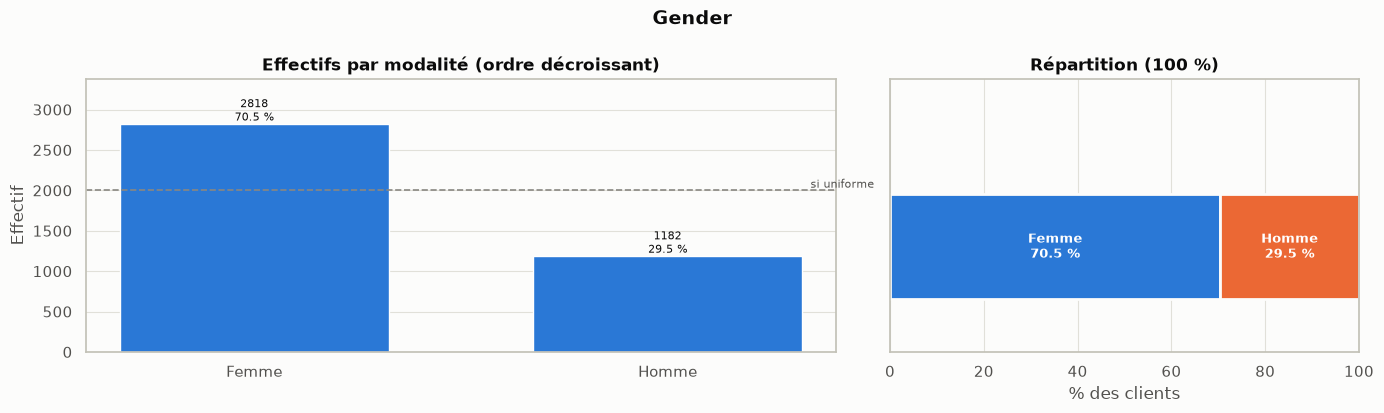

In [22]:
display(tableau_frequences(df["Gender"]))
graphiques(df["Gender"], "Gender")

### Interprétation — `Gender`
- Variable **binaire** (0 = Femme, 1 = Homme), sans valeur manquante.
- Les **femmes sont largement majoritaires** : **2 818 clientes (70,45 %)** contre **1 182 hommes (29,55 %)**, soit environ **2,4 femmes pour 1 homme**.
- Le test du χ² d'uniformité (χ² ≈ 669, p ≈ 0) rejette nettement l'hypothèse d'une répartition 50/50 : la sur-représentation féminine est **réelle**, elle ne s'explique pas par le hasard.
- La clientèle est donc **majoritairement féminine**, ce qui est à prendre en compte pour le ciblage marketing.
- Conséquence : dans les analyses bivariées, il faudra raisonner en **taux** (pourcentage d'achat chez les femmes vs chez les hommes) et non en effectifs bruts, puisque les hommes sont 2,4 fois moins nombreux.

## 6. Variable `Region` (région)

,Effectif,Fréquence (%),Fréq. cumulée (%)
Region,,,
NE,1657,41.42,41.42
SW,1270,31.75,73.17
SE,845,21.12,94.29
NW,228,5.70,99.99


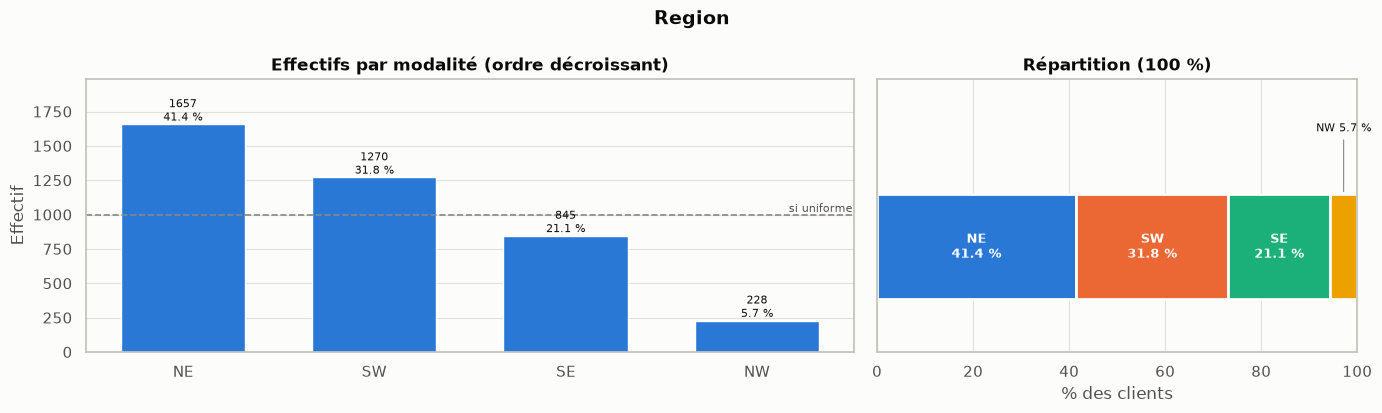

In [23]:
display(tableau_frequences(df["Region"]))
graphiques(df["Region"], "Region")

### Interprétation — `Region`
- 4 modalités (NE, SW, SE, NW), aucune valeur manquante.
- **NE** est la région dominante avec **1 657 clients (41,42 %)**, suivie de **SW (31,75 %)** et **SE (21,12 %)**. Ces trois régions regroupent **94,3 %** de la clientèle.
- **NW** est très peu représentée : **228 clients (5,70 %)**, soit environ **7 fois moins** que NE.
- Le test du χ² (χ² ≈ 1 125, p ≈ 0) confirme que la répartition est **très inégale**.
- Conséquence : les résultats concernant NW reposent sur un petit effectif et seront **moins fiables** (forte variabilité des taux). Selon l'objectif, on peut envisager de regrouper NW avec une région voisine.

## 7. Variable `CityCode` (code ville)

,Effectif,Fréquence (%),Fréq. cumulée (%)
CityCode,,,
M,234,5.85,5.85
N,224,5.60,11.45
I,223,5.58,17.03
C,219,5.48,22.51
L,219,5.48,27.99
F,216,5.40,33.39
H,213,5.32,38.71
S,209,5.22,43.93
E,206,5.15,49.08


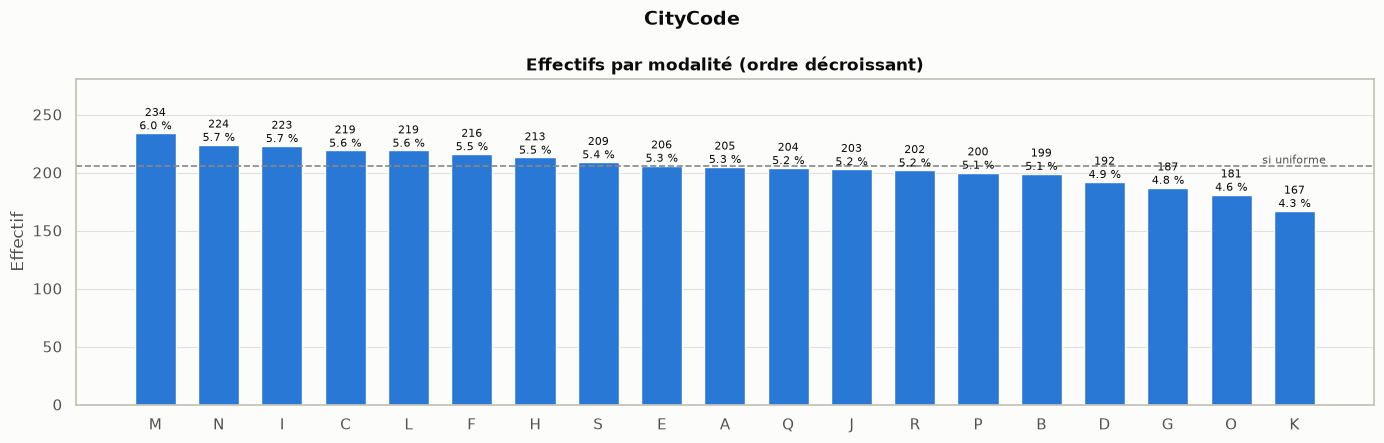

In [24]:
display(tableau_frequences(df["CityCode"]))
graphiques(df["CityCode"], "CityCode")

### Interprétation — `CityCode`
- **19 modalités** (lettres A à S) : c'est la variable qualitative la plus détaillée.
- **97 valeurs manquantes (2,43 %)**, une proportion faible : on peut les supprimer ou les regrouper dans une modalité « Inconnu » sans fausser l'analyse.
- La répartition est **quasi uniforme** : chaque ville représente entre **4,18 % (K, 167 clients)** et **5,85 % (M, 234 clients)** ; le ratio max/min n'est que de 1,4.
- Le test du χ² (χ² ≈ 22,9, **p ≈ 0,19 > 0,05**) indiquent qu'on **ne peut pas rejeter** l'hypothèse d'une répartition égale entre les villes.
- Conséquence : aucune ville ne domine. Prise seule, `CityCode` apporte **peu d'information**. Avec 19 modalités, elle risque surtout d'alourdir un modèle : à n'utiliser que si l'analyse bivariée montre un lien avec la cible.

## 8. Variable cible `ProvPur` (achat provincial)

,Effectif,Fréquence (%),Fréq. cumulée (%)
ProvPur,,,
No,3662,91.55,91.55
Yes,338,8.45,100.00


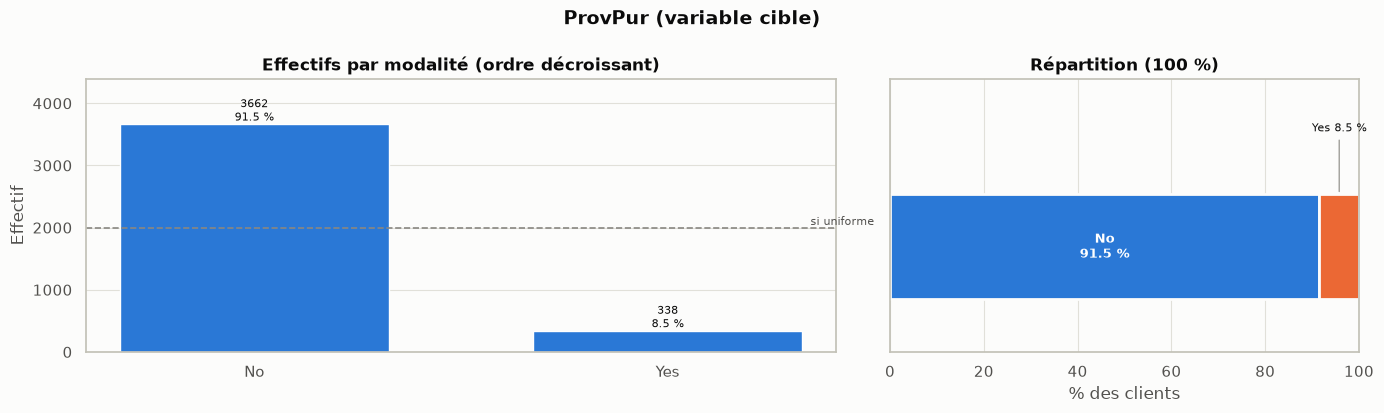

In [25]:
display(tableau_frequences(df[CIBLE]))
graphiques(df[CIBLE], "ProvPur (variable cible)")

### Interprétation — `ProvPur`
- Variable cible **binaire** (Yes / No), sans valeur manquante.
- **Seulement 338 clients (8,45 %)** ont réalisé un achat provincial, contre **3 662 (91,55 %)** qui n'en ont pas fait, soit environ **1 acheteur pour 11 non-acheteurs**.
- Le test du χ² est extrêmement significatif : la cible est **fortement déséquilibrée**.
- Conséquences pour la suite :
  - un modèle naïf qui prédirait toujours « No » aurait déjà **91,5 % d'exactitude** : l'*accuracy* n'est donc pas un bon indicateur. Il faut plutôt regarder le **rappel**, la **précision**, le **F1-score** ou l'**AUC** sur la classe « Yes » ;
  - il faut prévoir un **échantillonnage stratifié** (train/test) et éventuellement un rééquilibrage (pondération des classes, sur- ou sous-échantillonnage).

## 9. Indicateurs de tendance centrale adaptés aux variables qualitatives

Pour une variable qualitative, **on ne peut pas toujours calculer une moyenne ou une médiane**. Tout dépend de la **nature** de la variable :

| Nature | Exemple | Mode | Médiane | Moyenne |
|---|---|---|---|---|
| **Nominale** (modalités sans ordre) | `Region`, `CityCode` | ✅ | ❌ | ❌ |
| **Ordinale** (modalités ordonnées) | *aucune dans ce jeu de données* | ✅ | ✅ | ❌ |
| **Binaire** codée 0 / 1 | `Gender`, `ProvPur` | ✅ | ✅ | ✅ = **proportion** |

- **Nominale** : « NE + SW / 2 » n'a aucun sens. Seul le **mode** (modalité la plus fréquente) est un indicateur central valable.
- **Ordinale** : on pourrait ranger les modalités et trouver une **classe médiane**, mais aucune des variables qualitatives étudiées n'est ordinale.
- **Binaire 0/1** : la moyenne est égale à la **proportion de 1**. On peut donc lui associer un écart-type et un **intervalle de confiance**.

### 9.1 Variables nominales : seul le mode a un sens

In [26]:
nominales = ["Region", "CityCode"]
t_nom = pd.DataFrame({
    "Mode": [df[c].mode()[0] for c in nominales],
    "Effectif du mode": [df[c].value_counts().max() for c in nominales],
    "Part du mode (%)": [round(df[c].value_counts(normalize=True).max() * 100, 2) for c in nominales],
    "Nb modalités": [df[c].nunique() for c in nominales],
    "Part si uniforme (%)": [round(100 / df[c].nunique(), 2) for c in nominales],
}, index=nominales)
display(t_nom)

,Mode,Effectif du mode,Part du mode (%),Nb modalités,Part si uniforme (%)
Region,NE,1657,41.42,4,25.00
CityCode,M,234,6.00,19,5.26


**Interprétation**
- `Region` : le mode est **NE** avec **41,4 %** des clients, contre 25 % attendus si les 4 régions étaient égales. Le mode est donc **très marqué** : il décrit bien la région « typique » d'un client.
- `CityCode` : le mode est **M**, mais il ne regroupe que **6 %** des clients (hors manquants), à peine plus que les 5,3 % attendus en cas d'égalité. Le mode est **peu marqué** : aucune ville n'est vraiment « typique », et cet indicateur est peu informatif ici.

### 9.2 Variables binaires : moyenne = proportion, avec intervalle de confiance

In [27]:
def resume_binaire(s, modalite_1):
    """Recode la variable en 0/1 (1 = modalite_1) et calcule moyenne, médiane, écart-type et IC à 95 %."""
    x = (s == modalite_1).astype(int)
    n, p = len(x), x.mean()
    marge = 1.96 * np.sqrt(p * (1 - p) / n)
    return pd.Series({
        "Codage 1 =": modalite_1,
        "Moyenne (= proportion)": round(p, 4),
        "Médiane": x.median(),
        "Mode": x.mode()[0],
        "Écart-type": round(x.std(), 4),
        "IC 95 % bas (%)": round((p - marge) * 100, 2),
        "IC 95 % haut (%)": round((p + marge) * 100, 2),
    })

t_bin = pd.DataFrame({
    "Gender": resume_binaire(df["Gender"], "Homme"),
    CIBLE: resume_binaire(df[CIBLE], "Yes"),
}).T
display(t_bin)

,Codage 1 =,Moyenne (= proportion),Médiane,Mode,Écart-type,IC 95 % bas (%),IC 95 % haut (%)
Gender,Homme,0.2955,0.0,0,0.4563,28.14,30.96
ProvPur,Yes,0.0845,0.0,0,0.2782,7.59,9.31


**Interprétation**
- `Gender` (1 = Homme) : la **moyenne vaut 0,2955**, ce qui veut dire que **29,55 % des clients sont des hommes**. L'intervalle de confiance à 95 % va de **28,1 % à 31,0 %**. Même en tenant compte de l'incertitude, les hommes restent nettement minoritaires.
  - La **médiane et le mode valent 0 (Femme)** : plus de la moitié des clients sont des femmes.
- `ProvPur` (1 = Yes) : la **moyenne vaut 0,0845**, soit un **taux d'achat provincial de 8,45 %**, avec un intervalle de confiance de **7,6 % à 9,3 %**.
  - La **médiane et le mode valent 0 (No)** : le client « typique » n'achète pas.
  - Ce taux de base (≈ 8,5 %) servira de **référence** dans l'analyse bivariée. Un groupe avec un taux nettement supérieur sera considéré comme **sur-acheteur**.
- L'écart-type d'une variable binaire vaut √(p(1−p)). Il est maximal quand p = 0,5. Il est faible pour `ProvPur` (0,28), parce que presque tout le monde a la même réponse (« No »).

## 10. Visualisations complémentaires

Les graphiques des sections 5 à 8 décrivent chaque variable séparément. Ceux-ci les **comparent entre elles** et rendent visibles les indicateurs calculés plus haut : l'écart à l'uniformité (test du χ²) et l'intervalle de confiance des proportions.

### 10.1 Vue d'ensemble : la répartition des 4 attributs côte à côte

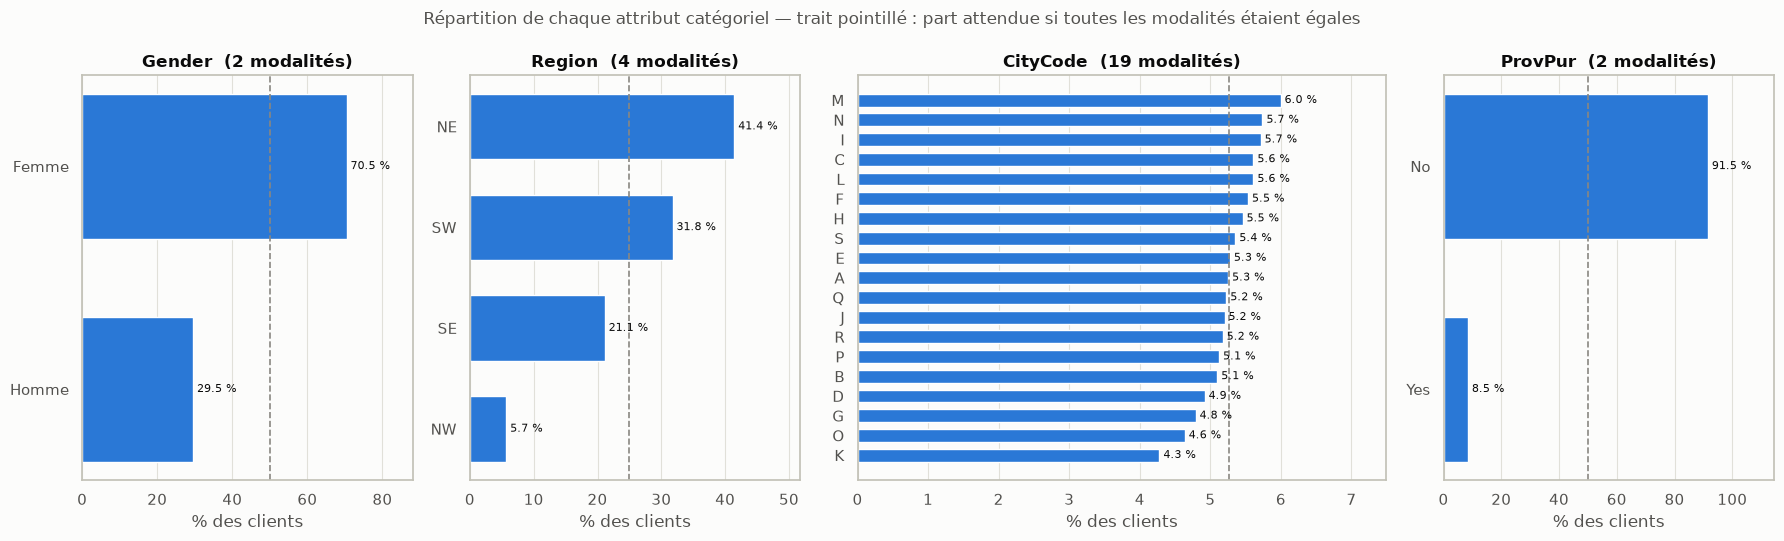

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.6, 1]})
for ax, c in zip(axes, QUALITATIVES):
    pct = df[c].value_counts(normalize=True).sort_values() * 100
    ax.barh(pct.index.astype(str), pct.values, color=BLEU, height=0.65)
    ax.axvline(100 / len(pct), color=GRIS, ls="--", lw=1.2)          # part si répartition uniforme
    for y, v in enumerate(pct.values):
        ax.text(v, y, f" {v:.1f} %", va="center", fontsize=8, color=ENCRE)
    ax.set_title(f"{c}  ({len(pct)} modalités)")
    ax.set_xlabel("% des clients"); ax.margins(x=0.25); ax.grid(axis="y", visible=False)
fig.suptitle("Répartition de chaque attribut catégoriel — trait pointillé : part attendue si toutes les modalités étaient égales",
             fontsize=12, color=ENCRE_2)
plt.tight_layout(); plt.show()

**Interprétation**
- Sur une même vue, on voit tout de suite quels attributs sont **déséquilibrés** : les barres s'éloignent fortement du trait pointillé pour `ProvPur`, `Gender` et `Region`.
- **`CityCode`** est l'exception : toutes les barres restent collées au trait (≈ 5,3 %), la répartition est **quasi uniforme**.
- Le déséquilibre le plus fort est celui de la **cible `ProvPur`** : la barre « No » est environ **11 fois** plus longue que la barre « Yes ».

### 10.2 Écart à la répartition uniforme (en points de %)

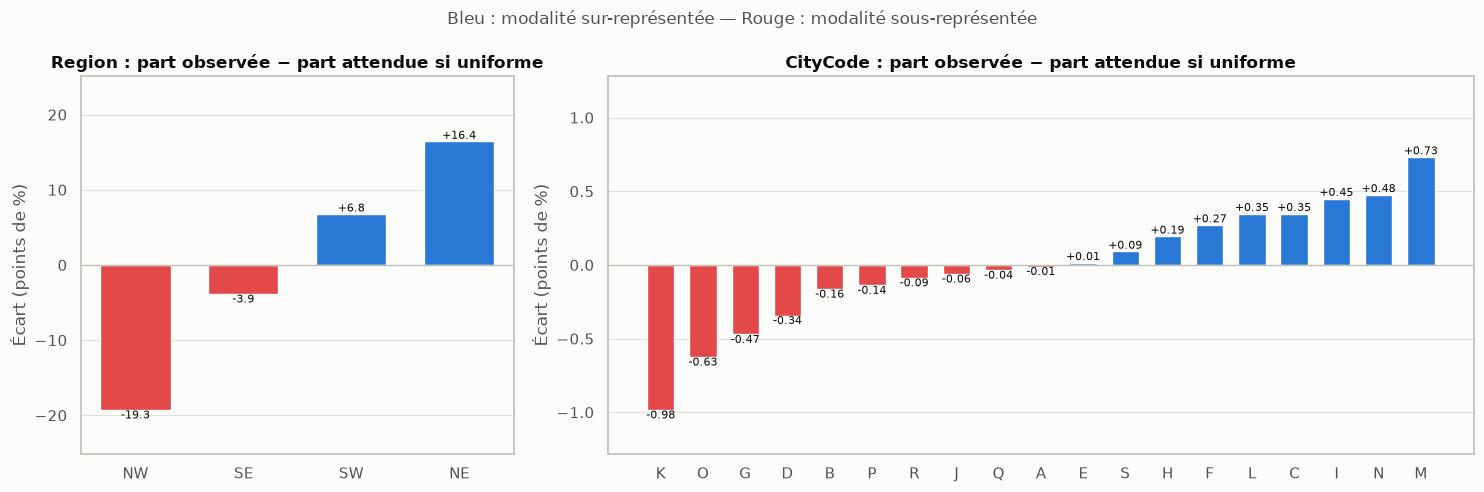

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 2]})
for ax, c in zip(axes, ["Region", "CityCode"]):
    pct = df[c].value_counts(normalize=True) * 100
    ecart = (pct - 100 / len(pct)).sort_values()
    couleurs = [BLEU if e > 0 else ROUGE for e in ecart]
    ax.bar(ecart.index.astype(str), ecart.values, color=couleurs, width=0.65)
    ax.axhline(0, color="#c3c2b7", lw=1)
    for x, e in enumerate(ecart.values):
        fmt = f"{e:+.2f}" if c == "CityCode" else f"{e:+.1f}"
        ax.text(x, e, fmt, ha="center", va="bottom" if e > 0 else "top", fontsize=8, color=ENCRE)
    ax.set_title(f"{c} : part observée − part attendue si uniforme")
    ax.set_ylabel("Écart (points de %)"); ax.margins(y=0.2); ax.grid(axis="x", visible=False)
    ymax = max(abs(ecart.min()), abs(ecart.max())) * 1.3
    ax.set_ylim(-ymax, ymax)                                # échelle symétrique autour de 0
fig.suptitle("Bleu : modalité sur-représentée — Rouge : modalité sous-représentée", fontsize=12, color=ENCRE_2)
plt.tight_layout(); plt.show()

**Interprétation**
- **`Region`** : **NE (+16,4 points)** et **SW (+6,8 points)** sont sur-représentées par rapport aux 25 % attendus, tandis que **NW (−19,3 points)** est fortement sous-représentée. Ces écarts expliquent le χ² très élevé (≈ 1 125).
- **`CityCode`** : les écarts restent **minuscules**, entre environ −1 et +1 point. C'est pourquoi le test du χ² ne rejette pas l'uniformité (p ≈ 0,19) : les villes sont représentées de façon **équivalente**.
- Attention à l'échelle : les deux graphiques n'ont **pas** le même axe vertical. Les écarts de `CityCode` sont environ **20 fois plus petits** que ceux de `Region`.

### 10.3 Proportions des attributs binaires et leur intervalle de confiance à 95 %

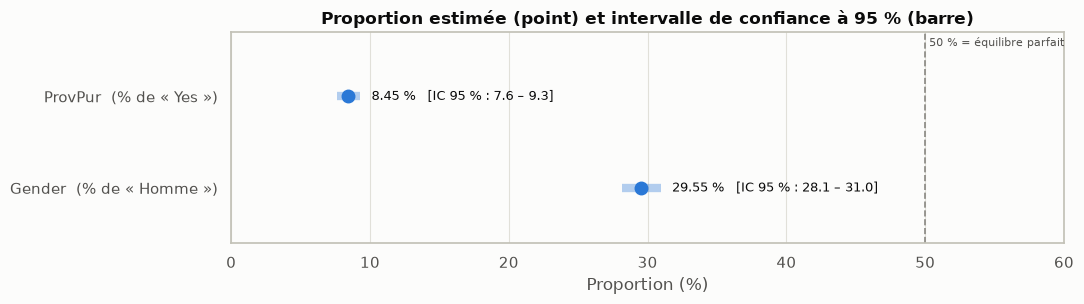

In [30]:
props = t_bin[["Moyenne (= proportion)", "IC 95 % bas (%)", "IC 95 % haut (%)"]].astype(float)
props["p (%)"] = props["Moyenne (= proportion)"] * 100
libelles = [f"{v}  (% de « {t_bin.loc[v, 'Codage 1 =']} »)" for v in props.index]

fig, ax = plt.subplots(figsize=(11, 3.2))
y = np.arange(len(props))
ax.hlines(y, props["IC 95 % bas (%)"], props["IC 95 % haut (%)"], color=BLEU, lw=6, alpha=0.35)
ax.plot(props["p (%)"], y, "o", color=BLEU, markersize=9)
for yi, (p, lo, hi) in enumerate(zip(props["p (%)"], props["IC 95 % bas (%)"], props["IC 95 % haut (%)"])):
    ax.text(hi + 0.8, yi, f"{p:.2f} %   [IC 95 % : {lo:.1f} – {hi:.1f}]", va="center", fontsize=9, color=ENCRE)
ax.axvline(50, color=GRIS, ls="--", lw=1.2)
ax.text(50, len(props) - 0.45, " 50 % = équilibre parfait", fontsize=8, color=ENCRE_2)
ax.set_yticks(y, libelles); ax.set_xlim(0, 60); ax.set_ylim(-0.6, len(props) - 0.3)
ax.set_xlabel("Proportion (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Proportion estimée (point) et intervalle de confiance à 95 % (barre)")
plt.tight_layout(); plt.show()

**Interprétation**
- Les intervalles de confiance sont **étroits** (environ ± 1,4 point pour `Gender`, ± 0,9 point pour `ProvPur`) parce que l'échantillon est grand (4 000 clients). Les proportions sont donc **estimées avec précision**.
- Les deux intervalles sont **très loin du trait des 50 %** : le déséquilibre des deux attributs binaires est certain, il n'est pas dû au hasard de l'échantillonnage.
- `ProvPur` est le plus éloigné de l'équilibre : on retrouve la **rareté de la cible** (≈ 8,5 % d'acheteurs).

## 11. Conclusion de l'analyse univariée qualitative

| Variable | Modalités | Manquants | Constat principal |
|---|---|---|---|
| `Gender` | 2 | 0 | Majorité de femmes : 70 % F / 30 % H |
| `Region` | 4 | 0 | NE majoritaire (41 %), NW marginale (6 %) |
| `CityCode` | 19 | 97 (2,4 %) | Répartition uniforme (≈ 5 % par ville), peu informative seule |
| `ProvPur` | 2 | 0 | Cible très déséquilibrée : 8,45 % de « Yes » |

**Tendance centrale** : seul le **mode** a un sens pour les variables nominales (NE pour `Region` ; aucun mode marqué pour `CityCode`). Pour les binaires, la **moyenne = proportion** : 29,6 % d'hommes et 8,45 % d'acheteurs provinciaux (IC 95 % : 7,6 – 9,3 %).

**Valeurs manquantes** : seules 97 valeurs de `CityCode` (2,43 %) manquent ; aucun code de manquant caché ; leur répartition est aléatoire (aucun lien avec le genre, la région ou la cible).

**À retenir** : la cible est rare, donc les analyses suivantes (bivariées et modélisation) doivent raisonner en **taux** et utiliser des métriques adaptées aux classes déséquilibrées. Les petits effectifs (région NW) sont à interpréter avec prudence.